# Customer Segmentation with Gaussian Mixture Models

**Team clustering project: GMM part**

An online gift retailer sells to thousands of customers, mostly wholesalers. A **Gaussian Mixture Model (GMM)** groups those customers by how they buy.

GMM is one of the four algorithms we compare, with K-Means, DBSCAN and Hierarchical clustering. All four read **the same prepared files** from `../data/processed/`, made by `../data/01_data_preparation.ipynb`. Any difference in the results therefore comes from the algorithms and not from the data.

| Part | What happens |
|---|---|
| 1. Data | load the prepared files |
| 2. GMM | how it works, choosing the number of components, fitting, soft assignments, noise test, profiles, product suggestions |
| 3. Wrap-up | strengths and weaknesses, key insights, results saved in this folder for the team comparison |

**Data:** [Online Retail dataset, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail) (Chen, Sain & Guo, 2012): all transactions of a UK-based online retailer between 01/12/2010 and 09/12/2011.

**Acknowledgement:** the data preparation in `../data/` is adapted from Farzad Nekouee's public notebook [Retail Customer Segmentation & Recommendation System](https://github.com/FarzadNekouee/Retail_Customer_Segmentation_Recommendation_System). The GMM analysis is our own.

---
# Part 1 · Data

## 1. Setup
Run this notebook from the `gmm/` folder. `RANDOM_STATE` is the same for the whole team.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse

from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

DATA_DIR = Path("../data/processed")       # prepared files shared by the team
RAW_PATH = "../data/raw/data.csv.gz"       # raw invoice lines (only for the product suggestions)
OUT_DIR = Path(".")                        # results are saved next to this notebook
RANDOM_STATE = 42

# plot style
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
MARKERS = ["o", "s", "^", "D", "v", "P"]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titlesize": 12, "font.size": 10, "figure.dpi": 110,
    "axes.axisbelow": True,
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 2. Load the prepared data
| file | what it is | used here for |
|---|---|---|
| `customer_pca.csv` | 4,143 customers x 5 PCA components | **fitting GMM** |
| `customer_features.csv` | the 12 readable features + `Country` + `IsOutlier`, all 4,362 customers | describing the clusters, and the noise test |
| `customer_features_transformed.csv` | the 12 features after the Yeo-Johnson transform | the profile heatmap |
| `customer_pca_all.csv` | the 5 components including the 219 extreme customers | the noise test |

See `../data/README.md` for how these files were made.

In [2]:
Z = pd.read_csv(DATA_DIR / "customer_pca.csv", index_col="CustomerID")                        # what we cluster
customers = pd.read_csv(DATA_DIR / "customer_features.csv", index_col="CustomerID")           # readable features
X = pd.read_csv(DATA_DIR / "customer_features_transformed.csv", index_col="CustomerID")       # transformed features
Z_all = pd.read_csv(DATA_DIR / "customer_pca_all.csv", index_col="CustomerID")                # Z + extreme customers

FEATURES = list(X.columns)
clean = customers.loc[Z.index].copy()                    # readable features of the customers we cluster
outliers = customers[customers["IsOutlier"]]
explained = Z.var(ddof=0) / X.var(ddof=0).sum()          # share of the variance each component keeps

assert X.index.equals(Z.index) and not clean["IsOutlier"].any()
print(f"clustering {len(Z):,} customers x {Z.shape[1]} components ({explained.sum():.0%} of the variance)")
print(f"extreme customers kept aside for the noise test: {len(outliers)}")
print("variance per component:", explained.round(2).to_dict())
Z.head()

clustering 4,143 customers x 5 components (89% of the variance)
extreme customers kept aside for the noise test: 219
variance per component: {'PC1': 0.44, 'PC2': 0.2, 'PC3': 0.11, 'PC4': 0.08, 'PC5': 0.06}


,PC1,PC2,PC3,PC4,PC5
CustomerID,,,,,
12346,-2.73,-2.99,2.13,1.00,0.47
12347,3.59,2.28,-1.24,-0.38,-0.81
12348,1.23,0.85,-0.99,-0.46,0.90
12349,0.55,5.87,1.94,0.01,-0.73
12350,-2.66,0.85,0.68,0.21,0.41


---
# Part 2 · Gaussian Mixture Model

## 3. How GMM works
GMM assumes the customers were generated by **k overlapping bell-shaped groups** (Gaussians). Each group has:
- a **mean**: its centre,
- a **covariance matrix**: its shape, size and tilt,
- a **weight**: what share of customers belongs to it.

These are learned with the **Expectation-Maximisation (EM)** algorithm, starting from a rough guess and repeating two steps until nothing changes:
1. **E-step**: for every customer, compute the probability of belonging to each group, given the current groups.
2. **M-step**: move, reshape and reweight each group to fit the customers, weighting each customer by those probabilities.

**Compared with K-Means**, GMM differs in two ways:

| | K-Means | GMM |
|---|---|---|
| assignment | hard: each customer in exactly one cluster | **soft**: a probability for every cluster |
| cluster shape | round, similar size | **ellipses** of any size and orientation (with `covariance_type="full"`) |

K-Means is in fact a special case of GMM: round groups of equal size where every customer is forced to 100% membership.

The settings we must choose:
- `n_components`: the number of groups.
- `covariance_type`: how flexible the shapes are. `spherical` gives round groups, `diag` gives axis-aligned ellipses, `tied` gives one shared shape, and `full` lets each group have its own tilted ellipse.

## 4. Choosing the number of components and the covariance type
GMM has no elbow plot of distances. Instead it gives a **likelihood**: how well the model explains the data. More components always raise the likelihood, so we use criteria that **penalise complexity**:
- **BIC** (Bayesian Information Criterion): lower is better, with a strong penalty per parameter.
- **AIC**: the same idea with a weaker penalty, so it tends to prefer more components.

We try 1-10 components with all four covariance types, using 5 random starts each.

all fits converged: True


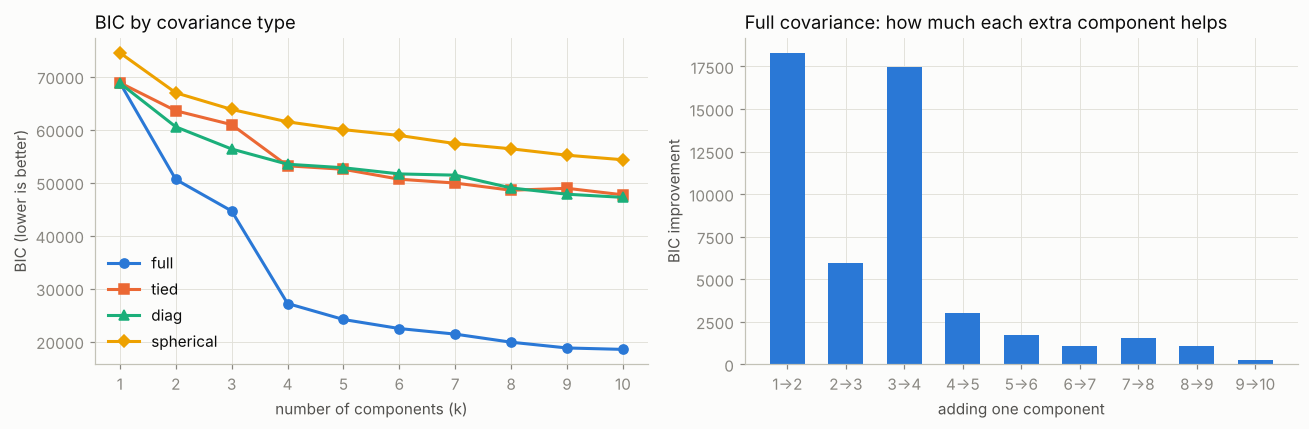

,BIC,BIC improvement,AIC,silhouette
k,,,,
1,"68,859.52",NaN,"68,732.94",NaN
2,"50,598.26","18,261.26","50,338.76",0.34
3,"44,640.70","5,957.56","44,248.29",0.35
4,"27,179.55","17,461.16","26,654.22",0.31
5,"24,160.87","3,018.67","23,502.64",0.33
6,"22,453.28","1,707.60","21,662.13",0.31
7,"21,399.29","1,053.98","20,475.23",0.29
8,"19,873.66","1,525.63","18,816.69",0.23
9,"18,787.61","1,086.05","17,597.72",0.18


In [3]:
rows = []
for cov in ["full", "tied", "diag", "spherical"]:
    for k in range(1, 11):
        gm = GaussianMixture(n_components=k, covariance_type=cov, n_init=5,
                             random_state=RANDOM_STATE).fit(Z)
        sil = silhouette_score(Z, gm.predict(Z)) if k > 1 else np.nan
        rows.append({"covariance": cov, "k": k, "BIC": gm.bic(Z), "AIC": gm.aic(Z),
                     "silhouette": sil, "converged": gm.converged_})
selection = pd.DataFrame(rows)
print("all fits converged:", selection["converged"].all())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, cov in enumerate(["full", "tied", "diag", "spherical"]):
    s = selection[selection.covariance == cov]
    axes[0].plot(s.k, s.BIC, marker=MARKERS[i], color=COLORS[i], lw=2, label=cov)
axes[0].set_xlabel("number of components (k)"); axes[0].set_ylabel("BIC (lower is better)")
axes[0].set_xticks(range(1, 11))
axes[0].legend(frameon=False); axes[0].set_title("BIC by covariance type")

full = selection[selection.covariance == "full"].set_index("k")
gain = -full["BIC"].diff().dropna()
axes[1].bar(gain.index, gain.values, color=COLORS[0], width=0.6)
axes[1].set_xticks(gain.index, [f"{k-1}→{k}" for k in gain.index])
axes[1].set_xlabel("adding one component"); axes[1].set_ylabel("BIC improvement")
axes[1].set_title("Full covariance: how much each extra component helps")
plt.tight_layout(); plt.show()

full.assign(**{"BIC improvement": gain})[["BIC", "BIC improvement", "AIC", "silhouette"]].round(3)

**Full covariance wins at every k, by a wide margin.** The groups are stretched, tilted ellipses. Spherical, the round shape K-Means assumes, fits worst.

**BIC never reaches a minimum.** It keeps falling all the way to 10 components because many customers share exactly the same value in some features: every one-time buyer has a purchase gap of exactly 0, and about two-thirds of customers never cancel. GMM can always gain a little likelihood by placing another narrow component on such a spike. We therefore look for the point where extra components stop paying off:
- going from 3 to 4 components improves BIC by **17,461**,
- going from 4 to 5 improves it by only **3,019**, and the gains keep shrinking after that.

Silhouette stays between 0.31 and 0.35 for 2-6 components and drops after 7. **We choose k = 4 with full covariance.**

In [4]:
N_CLUSTERS = 4
COV_TYPE = "full"

# stability: refit with single random starts and compare with a 10-start reference fit
reference = GaussianMixture(N_CLUSTERS, covariance_type=COV_TYPE, n_init=10,
                            random_state=RANDOM_STATE).fit(Z)
ref_labels = reference.predict(Z)
aris = [adjusted_rand_score(ref_labels,
                            GaussianMixture(N_CLUSTERS, covariance_type=COV_TYPE, n_init=1,
                                            random_state=seed).fit(Z).predict(Z))
        for seed in range(10)]
print("agreement with the reference fit (ARI, 1 = identical) for 10 single-start runs:")
print(np.round(aris, 2), f"| mean {np.mean(aris):.2f}")

agreement with the reference fit (ARI, 1 = identical) for 10 single-start runs:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.] | mean 1.00


All 10 single-start runs found **exactly the same four clusters** as the 10-start fit (ARI = 1.00), so with 4 components the result does not depend on where EM starts.

## 5. The final model
We keep the 10-start fit. Cluster numbers from GMM are arbitrary, so we **renumber the clusters by median total spend** (0 = lowest), which keeps them consistent between runs.

In [5]:
gmm = reference
order = np.argsort([clean.loc[ref_labels == c, "Total_Spend"].median() for c in range(N_CLUSTERS)])
relabel = {old: new for new, old in enumerate(order)}

labels = np.array([relabel[c] for c in ref_labels])
proba = gmm.predict_proba(Z)[:, order]          # columns now follow the new numbering
max_proba = proba.max(axis=1)

clean["Cluster"] = labels
sizes = pd.Series(labels).value_counts().sort_index()

metrics = pd.Series({
    "clusters": N_CLUSTERS,
    "silhouette (higher is better, -1..1)": silhouette_score(Z, labels),
    "Davies-Bouldin (lower is better)": davies_bouldin_score(Z, labels),
    "Calinski-Harabasz (higher is better)": calinski_harabasz_score(Z, labels),
    "customers with < 70% certainty": (max_proba < 0.7).mean(),
})
print("cluster sizes:", sizes.to_dict())
metrics.to_frame("GMM")

cluster sizes: {0: 1288, 1: 1311, 2: 360, 3: 1184}


,GMM
clusters,4.00
"silhouette (higher is better, -1..1)",0.31
Davies-Bouldin (lower is better),2.45
Calinski-Harabasz (higher is better),"1,132.30"
customers with < 70% certainty,0.02


In [6]:
# the same matrix and k with K-Means, as a reference point for the team comparison
km = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE).fit(Z)
print(f"K-Means silhouette with k={N_CLUSTERS}: {silhouette_score(Z, km.labels_):.3f}")
print(f"agreement GMM vs K-Means (ARI): {adjusted_rand_score(labels, km.labels_):.2f}")

K-Means silhouette with k=4: 0.364
agreement GMM vs K-Means (ARI): 0.67


The clusters have 1,288, 1,311, 360 and 1,184 customers. A silhouette of **0.31** means the clusters touch each other, which is normal for customer behaviour that changes gradually rather than in jumps. Only **1.5%** of customers are below 70% certainty.

K-Means on the same data and k reaches a higher silhouette (0.36). That does not automatically make K-Means better: silhouette rewards compact, round clusters, which is exactly what K-Means builds. The two methods agree only moderately (ARI 0.67), so they divide the customers differently. This is worth discussing in the team comparison.

## 6. Seeing the clusters
The model was fitted in all PCA dimensions, and here we look at the first two. Each ellipse is the model's own picture of a cluster: its centre and its covariance projected onto PC1 and PC2, drawn at about 2 standard deviations. Different sizes and tilts are something K-Means cannot represent.

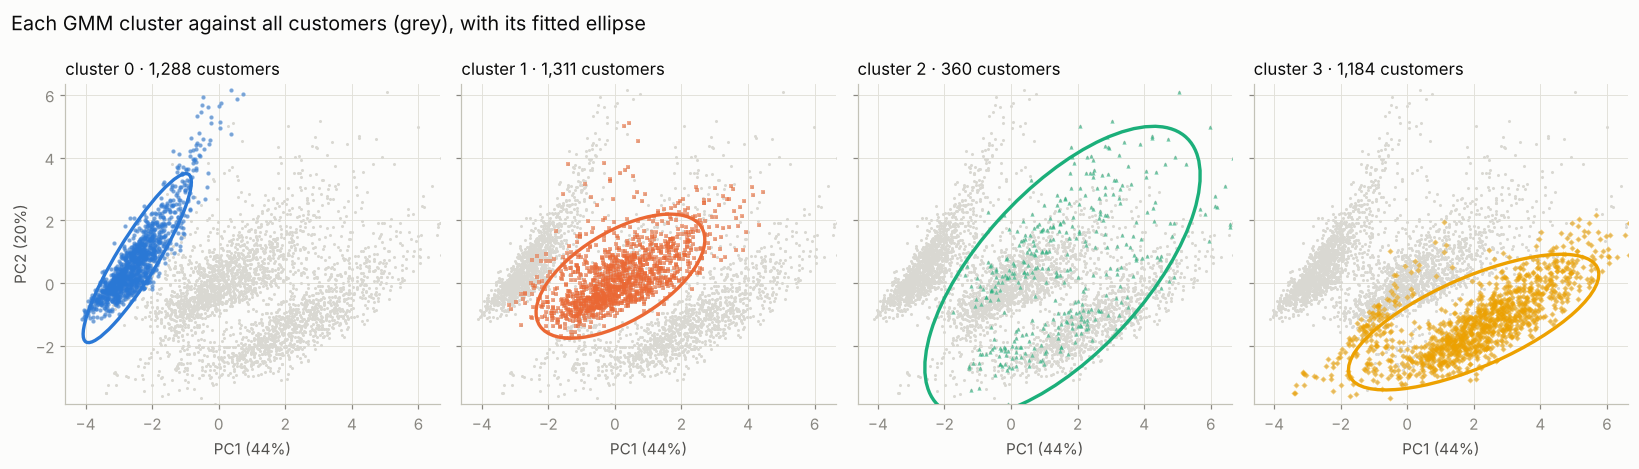

22 extreme customers lie outside this zoomed view


In [7]:
def draw_ellipse(ax, mean, cov, color):
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vecs[1, -1], vecs[0, -1]))
    width, height = 2 * 2 * np.sqrt(vals[::-1])          # ~2 standard deviations
    ax.add_patch(Ellipse(mean, width, height, angle=angle, fill=False, lw=2.2, color=color, zorder=3))

# zoom on the bulk of the data; a few extreme customers would otherwise squash the view
lo, hi = Z[["PC1", "PC2"]].quantile(0.005), Z[["PC1", "PC2"]].quantile(0.995)
pad = (hi - lo) * 0.08
xlim, ylim = (lo.PC1 - pad.PC1, hi.PC1 + pad.PC1), (lo.PC2 - pad.PC2, hi.PC2 + pad.PC2)
hidden = ~Z["PC1"].between(*xlim) | ~Z["PC2"].between(*ylim)

fig, axes = plt.subplots(1, N_CLUSTERS, figsize=(15, 4.3), sharex=True, sharey=True)
for c, ax in enumerate(axes):
    m = labels == c
    ax.scatter(Z["PC1"], Z["PC2"], s=4, color="#d9d8d2", linewidths=0)
    ax.scatter(Z.loc[m, "PC1"], Z.loc[m, "PC2"], s=8, color=COLORS[c], marker=MARKERS[c],
               alpha=0.55, linewidths=0)
    old = order[c]
    draw_ellipse(ax, gmm.means_[old, :2], gmm.covariances_[old][:2, :2], COLORS[c])
    ax.set_title(f"cluster {c} · {m.sum():,} customers", fontsize=11)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel(f"PC1 ({explained.iloc[0]:.0%})")
axes[0].set_ylabel(f"PC2 ({explained.iloc[1]:.0%})")
fig.suptitle("Each GMM cluster against all customers (grey), with its fitted ellipse",
             x=0.01, ha="left", fontsize=13)
plt.tight_layout(); plt.show()
print(f"{hidden.sum()} extreme customers lie outside this zoomed view")

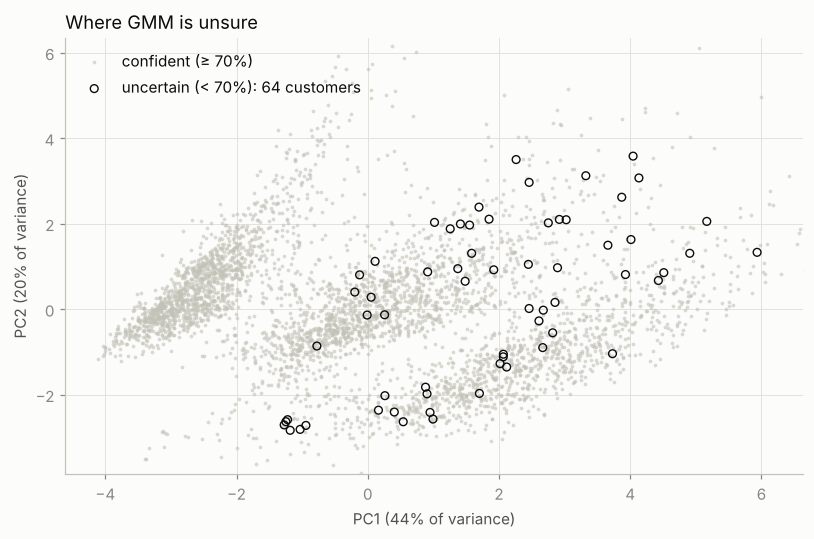

In [8]:
unsure = max_proba < 0.7
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(Z.loc[~unsure, "PC1"], Z.loc[~unsure, "PC2"], s=6, color="#c3c2b7", alpha=0.6,
           linewidths=0, label="confident (≥ 70%)")
ax.scatter(Z.loc[unsure, "PC1"], Z.loc[unsure, "PC2"], s=26, facecolors="none", edgecolors=INK,
           lw=0.9, label=f"uncertain (< 70%): {unsure.sum()} customers")
ax.set_xlim(xlim); ax.set_ylim(ylim)
ax.set_xlabel(f"PC1 ({explained.iloc[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({explained.iloc[1]:.0%} of variance)")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Where GMM is unsure")
plt.tight_layout(); plt.show()

- **Cluster 0** is a tight, tilted ellipse set apart on the left.
- **Clusters 1 and 3** overlap in this view. They are separated along other components, since cancellations load mainly on PC2 and PC3, and a 2D picture only partly shows that.
- **Cluster 2** is small but very wide, spreading across the other clouds. GMM often creates one broad component like this to collect customers who fit no tight group. K-Means cannot, because all its clusters are compact.

The uncertain customers sit on the borders between clusters 1, 2 and 3, never inside the cluster-0 cloud.

## 7. Soft assignments
GMM gives each customer a probability for every cluster, which none of the other three algorithms do. Customers whose highest probability is low sit between segments, and in practice they are the ones a marketing team should not target too confidently.

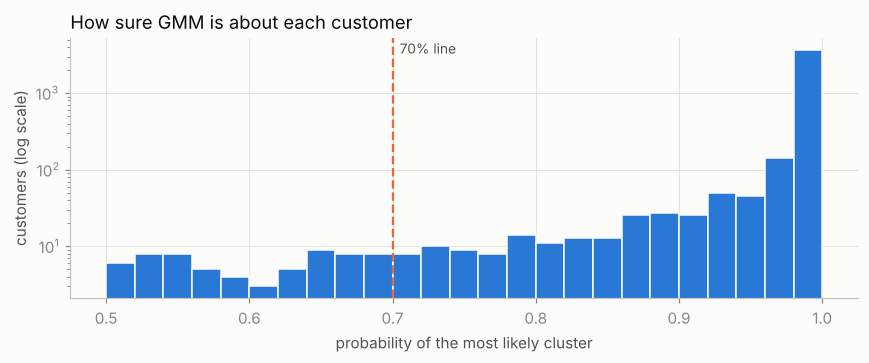

certainty ≥ 99%: 84.2% | below 70%: 1.5%
the five most uncertain customers:


,P(cluster 0),P(cluster 1),P(cluster 2),P(cluster 3),Cluster
CustomerID,,,,,
12714,0.00,0.50,0.50,0.00,2
17937,0.00,0.51,0.49,0.00,1
12908,0.00,0.00,0.51,0.49,2
13209,0.00,0.00,0.52,0.48,2
13437,0.00,0.52,0.48,0.00,1


In [9]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(np.floor(max_proba.min() * 20) / 20, 1.0, 26)
ax.hist(max_proba, bins=bins, color=COLORS[0], edgecolor="#fcfcfb", linewidth=1)
ax.axvline(0.7, color=COLORS[1], ls="--", lw=1.5)
ax.text(0.705, ax.get_ylim()[1] * 0.85, "70% line", color=INK2, fontsize=9)
ax.set_yscale("log")
ax.set_xlabel("probability of the most likely cluster"); ax.set_ylabel("customers (log scale)")
ax.set_title("How sure GMM is about each customer")
plt.tight_layout(); plt.show()

prob_table = pd.DataFrame(proba, index=Z.index, columns=[f"P(cluster {c})" for c in range(N_CLUSTERS)])
print(f"certainty ≥ 99%: {(max_proba >= 0.99).mean():.1%} | below 70%: {(max_proba < 0.7).mean():.1%}")
print("the five most uncertain customers:")
prob_table.assign(Cluster=labels).iloc[np.argsort(max_proba)[:5]].round(2)

**84.2%** of customers are assigned with at least 99% certainty, and only **64 customers (1.5%)** fall below 70%. The five most uncertain customers are split almost 50/50, and each one involves cluster 2. This matches the picture above: the wide cluster 2 overlaps its neighbours. K-Means would place these customers firmly in one cluster and give no sign of the doubt.

## 8. Sensitivity to noise
GMM has no "noise" label: every customer is forced into some cluster. We test what that means in two ways:
1. **Refit with the set-aside customers included** (transform, PCA and GMM all refitted) and check whether the regular customers keep their clusters.
2. **Use GMM as a noise detector.** The fitted model gives every customer a *density*, meaning how typical they are. We score the 219 extreme customers from `customer_pca_all.csv`: customers the model finds very unlikely are candidates for noise, which is how GMM can partly do what DBSCAN does.

In [10]:
# 1) refit on all customers, outliers included
power_all = PowerTransformer(method="yeo-johnson").fit(customers[FEATURES])
Z_refit = PCA(n_components=Z.shape[1]).fit_transform(power_all.transform(customers[FEATURES]))
gmm_all = GaussianMixture(N_CLUSTERS, covariance_type=COV_TYPE, n_init=10,
                          random_state=RANDOM_STATE).fit(Z_refit)
labels_all = gmm_all.predict(Z_refit)
is_out = customers["IsOutlier"].to_numpy()

# match the new clusters to our numbering (by where the regular customers ended up)
match = pd.crosstab(labels_all[~is_out], labels).idxmax(axis=1).to_dict()
labels_all = np.array([match[c] for c in labels_all])

print(f"agreement on the {(~is_out).sum():,} regular customers (ARI): "
      f"{adjusted_rand_score(labels, labels_all[~is_out]):.2f}")
print(f"regular customers that changed cluster: {(labels != labels_all[~is_out]).mean():.1%}")
print("the outliers were absorbed into clusters:",
      pd.Series(labels_all[is_out]).value_counts().sort_index().to_dict())

# 2) density of the outliers under the clean model
dens_clean = gmm.score_samples(Z)
Z_out = Z_all.loc[Z_all["IsOutlier"], Z.columns]      # extreme customers, same space as Z
dens_out = gmm.score_samples(Z_out)
cut = np.percentile(dens_clean, 5)
print(f"outliers below the 5th percentile of normal-customer density: {(dens_out < cut).mean():.0%}")
print(f"median log-density: regular {np.median(dens_clean):.1f} | set aside {np.median(dens_out):.1f}")

agreement on the 4,143 regular customers (ARI): 0.83
regular customers that changed cluster: 9.1%
the outliers were absorbed into clusters: {1: 1, 2: 142, 3: 76}
outliers below the 5th percentile of normal-customer density: 83%
median log-density: regular -4.9 | set aside -15.5


**Outliers pull the model but do not break it.** With the 219 extreme customers included, **9.1%** of regular customers change cluster (ARI 0.83). The outliers are absorbed mainly into the two high-spending clusters (142 into cluster 2 and 76 into cluster 3), which stretches those clusters. GMM has no way to say "this customer belongs nowhere".

**GMM's density still recognises them.** 83% of the set-aside customers fall below the density of the least typical 5% of regular customers, and their median log-density is -15.5 against -4.9. A density threshold therefore turns GMM into a reasonable noise detector, but it is a step we have to add ourselves. DBSCAN labels noise automatically.

## 9. Who is in each cluster?
The clusters were built in PCA space, so to describe them we go back to the readable features. The table shows **medians**, which a few big customers cannot distort. The heatmap shows each cluster's average on the transformed features, where 0 is the average customer.

In [11]:
profile = clean.groupby("Cluster")[FEATURES].median()
profile.insert(0, "customers", sizes.values)
profile["share of all customers"] = sizes.values / len(clean)
profile["one-time buyers"] = (clean["N_Invoices"] == 1).groupby(clean["Cluster"]).mean()
profile["have cancelled"] = (clean["N_Cancellations"] > 0).groupby(clean["Cluster"]).mean()
profile["UK customers"] = (clean["Country"] == "United Kingdom").groupby(clean["Cluster"]).mean()
profile["share of total spend"] = clean.groupby("Cluster")["Total_Spend"].sum() / clean["Total_Spend"].sum()
profile.T

Cluster,0,1,2,3
customers,"1,288.00","1,311.00",360.00,"1,184.00"
Recency_Days,127.50,38.00,42.00,26.00
N_Invoices,1.00,3.00,3.00,6.00
Total_Quantity,136.00,422.00,727.00,745.50
Total_Spend,234.20,709.71,"1,162.16","1,332.88"
Unique_Products,15.00,42.00,51.50,61.00
Avg_Invoice_Value,234.20,229.25,357.59,204.23
Avg_Days_Between_Purchases,0.00,70.75,31.00,51.07
N_Cancellations,0.00,0.00,0.00,1.00
Cancellation_Rate,0.00,0.00,0.00,0.25


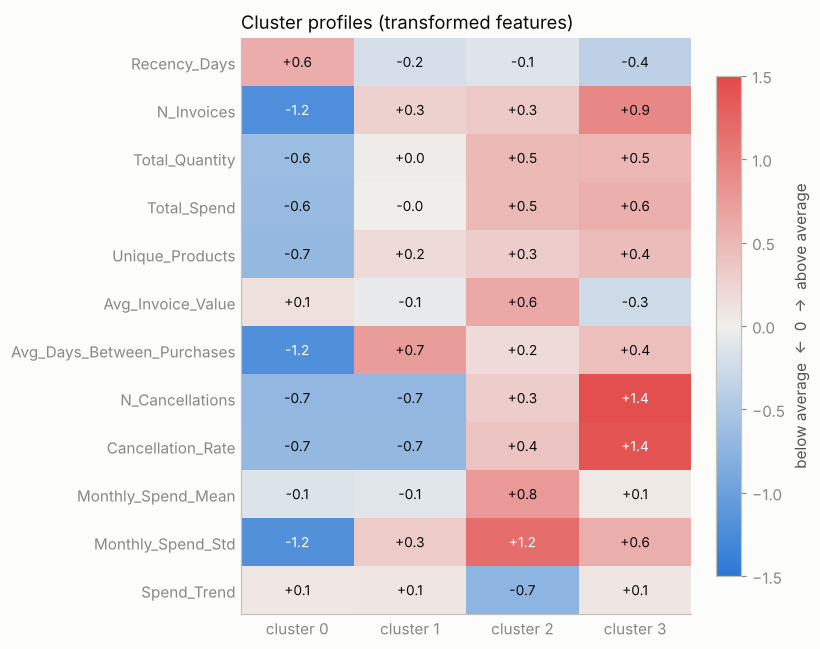

In [12]:
heat = X.groupby(labels).mean()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(heat.T, cmap=DIVERGING, vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(N_CLUSTERS), [f"cluster {c}" for c in range(N_CLUSTERS)])
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for c in range(N_CLUSTERS):
        v = heat.iloc[c, i]
        ax.text(c, i, f"{v:+.1f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 1.0 else INK)
ax.grid(False); ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.05); cb.set_label("below average  ←  0  →  above average")
ax.set_title("Cluster profiles (transformed features)")
plt.tight_layout(); plt.show()

Reading the table and the heatmap together:

| cluster | name | who they are |
|---|---|---|
| 0 | **One-time buyers** | 31% of customers, all with exactly one purchase, which was the longest ago (about 128 days, median). A single basket of about £234. Only **9%** of total spend. |
| 1 | **Steady repeat buyers** | 32% of customers. About 3 purchases, roughly every 71 days, and none of them ever cancelled. Moderate, even spending (median £710). **29%** of total spend. |
| 2 | **Big baskets, slowing down** | 9% of customers. The largest baskets (£358 per invoice, £516 per month), but very uneven from month to month, and the only group whose spending is clearly **falling** (median -£161 per month). About half have cancelled at least once. **14%** of total spend. |
| 3 | **Frequent buyers who return items** | 29% of customers. The most active and most recent group: 6 invoices, last purchase 26 days ago, highest total spend (£1,333). Every one of them has cancelled at least once, about a quarter of their invoices. **48%** of total spend. |

Between 87% and 93% of each cluster is in the UK, so the segments reflect behaviour, not geography.

In [13]:
SEGMENT_NAMES = {
    0: "One-time buyers",
    1: "Steady repeat buyers",
    2: "Big baskets, slowing down",
    3: "Frequent buyers who return items",
}
clean["Segment"] = clean["Cluster"].map(SEGMENT_NAMES)
clean["Segment"].value_counts()

Segment
Steady repeat buyers                1311
One-time buyers                     1288
Frequent buyers who return items    1184
Big baskets, slowing down            360
Name: count, dtype: int64

## 10. Putting the segments to use: simple product suggestions
For every segment we take its 10 best-selling products, measured by quantity bought after returns. Each customer is then offered the three most popular of those that they have **not** bought yet. This is a simple baseline that shows how a segment label turns into an action.

Suggestions need the individual invoice lines, which the prepared files do not contain, so this section reads the raw file and applies the same cleaning rules as `01_data_preparation.ipynb`.

In [14]:
lines = pd.read_csv(RAW_PATH, encoding="ISO-8859-1", compression="gzip",
                    dtype={"InvoiceNo": str, "StockCode": str})
lines = lines.dropna(subset=["CustomerID", "Description"]).drop_duplicates()
non_product = (lines["StockCode"].str.count(r"\d") < 2) | \
              lines["Description"].isin(["Next Day Carriage", "High Resolution Image"])
lines = lines[~non_product & (lines["UnitPrice"] > 0)].copy()
lines["CustomerID"] = lines["CustomerID"].astype(int)
lines["Description"] = lines["Description"].str.upper().str.strip()
lines["IsCancelled"] = lines["InvoiceNo"].str.startswith("C")
lines = lines.merge(clean[["Segment"]], left_on="CustomerID", right_index=True)

# summing purchases AND cancellations gives quantity net of returns
top = (lines.groupby(["Segment", "StockCode", "Description"])["Quantity"].sum()
       .reset_index().sort_values(["Segment", "Quantity"], ascending=[True, False])
       .groupby("Segment").head(10))
bought = lines[~lines["IsCancelled"]].groupby("CustomerID")["StockCode"].agg(set)

def suggest(customer_id, n=3):
    seg = clean.at[customer_id, "Segment"]
    owned = bought.get(customer_id, set())
    picks = top[(top["Segment"] == seg) & ~top["StockCode"].isin(owned)]
    return picks["Description"].head(n).tolist()

recommendations = pd.Series({cid: suggest(cid) for cid in clean.index}, name="suggested products")
print("top 3 products per segment:")
display(top.groupby("Segment").head(3)[["Segment", "Description", "Quantity"]])
example = recommendations.sample(5, random_state=RANDOM_STATE)
pd.DataFrame({"segment": clean.loc[example.index, "Segment"],
              "suggested products": example.apply(" | ".join)})

top 3 products per segment:


,Segment,Description,Quantity
24,"Big baskets, slowing down",SMALL CHINESE STYLE SCISSOR,8004
1286,"Big baskets, slowing down",PACK OF 12 LONDON TISSUES,5707
2508,"Big baskets, slowing down",WORLD WAR 2 GLIDERS ASSTD DESIGNS,4320
5801,Frequent buyers who return items,WORLD WAR 2 GLIDERS ASSTD DESIGNS,12584
6024,Frequent buyers who return items,ASSORTED COLOUR BIRD ORNAMENT,10749
6194,Frequent buyers who return items,WHITE HANGING HEART T-LIGHT HOLDER,8339
9044,One-time buyers,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2508
9333,One-time buyers,JUMBO BAG RED RETROSPOT,1467
8905,One-time buyers,SOMBRERO,1425
9659,Steady repeat buyers,BROCADE RING PURSE,6878


,segment,suggested products
15708,Frequent buyers who return items,WORLD WAR 2 GLIDERS ASSTD DESIGNS | ASSORTED C...
15179,Frequent buyers who return items,ASSORTED COLOUR BIRD ORNAMENT | WHITE HANGING ...
14628,Steady repeat buyers,BROCADE RING PURSE | JUMBO BAG RED RETROSPOT |...
12750,One-time buyers,WORLD WAR 2 GLIDERS ASSTD DESIGNS | JUMBO BAG ...
12560,Frequent buyers who return items,WORLD WAR 2 GLIDERS ASSTD DESIGNS | ASSORTED C...


---
# Part 3 · Wrap-up

## 11. GMM: strengths and weaknesses on this data

**Strengths we saw**
- **Flexible cluster shapes.** Full covariance beat every simpler shape by a wide BIC margin, and the fitted ellipses differ clearly in size and tilt (Section 6).
- **Probabilities instead of hard labels.** 64 customers (1.5%) are flagged as uncertain and the rest are near-certain. A marketing team can target only confident members.
- **A model-based way to choose k.** BIC and AIC judge the whole probability model, not only distances.
- **Density as a noise score.** 83% of the extreme customers land in the lowest 5% of density.
- **Stable.** Ten random starts gave identical clusters.

**Weaknesses we saw**
- **It needs bell-shaped data.** The raw money features are far from that, and GMM only became usable after the Yeo-Johnson transform in the data preparation.
- **BIC had no clear minimum.** Features with many exact zeros let GMM keep adding narrow components, so choosing k still took judgement (the elbow at 4).
- **No noise label.** Extreme customers are forced into clusters, and including them moved 9.1% of regular customers.
- **Many parameters.** Each full-covariance component in 5 dimensions needs 5 means and 15 covariance values, 83 parameters in total for 4 components. That is why PCA came first.
- **A broad catch-all component** (cluster 2) is harder to describe than compact clusters.
- **Lower silhouette than K-Means** (0.31 vs 0.36). Ranked on silhouette alone, GMM looks worse even when its clusters are meaningful.

**When we would use GMM:** when groups overlap or differ in size and shape, or when a probability per customer is needed (scoring, cautious targeting). DBSCAN is the better choice when noise must be labelled or clusters have irregular, non-elliptical shapes, and K-Means when speed and simple round clusters are enough.

## 12. Key insights

1. **Four behaviour segments**: one-time buyers (31% of customers, 9% of spend), steady repeat buyers (32%, 29%), big baskets slowing down (9%, 14%) and frequent buyers who return items (29%, 48%).
2. **Revenue is concentrated.** Under a third of the customers (cluster 3) produce almost half of the spend. Their frequent returns are a cost to manage, not a reason to push them away.
3. **Cluster 2 is the early warning.** High-value customers whose spending is falling are the natural target for a retention offer.
4. **One-time buyers are the largest group.** A second-purchase campaign is the obvious action.
5. **Method:** full covariance clearly beats simpler shapes, BIC flattens after 4 components, the result is identical across random starts, and only 1.5% of customers are uncertain.
6. **For the team comparison:** at k=4, GMM has a silhouette of 0.31 against 0.36 for K-Means, and the two agree at ARI 0.67. On noise, GMM absorbs outliers (9.1% of regular customers move) but can flag them through density. On shape, GMM fits stretched ellipses of different sizes.

## 13. Saving results for the team comparison
Saved in this `gmm/` folder:
- `gmm_segments.csv`: each customer's cluster, segment name, probability for every cluster and certainty.
- `labels_gmm.npy` and `proba_gmm.npy`: the same labels and probabilities, in the row order of `../data/processed/customer_pca.csv`.
- `gmm_recommendations.csv`: the suggested products.

In [15]:
result = prob_table.copy()
result.insert(0, "Cluster", labels)
result.insert(1, "Segment", clean["Segment"])
result["Certainty"] = max_proba
result.to_csv(OUT_DIR / "gmm_segments.csv", index_label="CustomerID")
np.save(OUT_DIR / "labels_gmm.npy", labels)
np.save(OUT_DIR / "proba_gmm.npy", proba)
recommendations.apply(" | ".join).to_csv(OUT_DIR / "gmm_recommendations.csv", index_label="CustomerID")

assert result.index.equals(Z.index)
saved = ["gmm_segments.csv", "labels_gmm.npy", "proba_gmm.npy", "gmm_recommendations.csv"]
assert all((OUT_DIR / f).exists() for f in saved)
print("saved:", saved)

saved: ['gmm_segments.csv', 'labels_gmm.npy', 'proba_gmm.npy', 'gmm_recommendations.csv']
